# Imports

In [1]:
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from datasets import Dataset, DatasetDict, load_dataset
from sklearn.model_selection import train_test_split
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers, processors
from sacrebleu.metrics import BLEU, CHRF
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_float32_matmul_precision('high')
print(device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name())
ARTIFACTS = Path('decoder_1_artifacts')
ARTIFACTS.mkdir(exist_ok=True)

/home/azavgorodnev/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda
NVIDIA H100 80GB HBM3


# Choose the dataset

Get the dataset from [here](https://tatoeba.org/en/downloads). Preferably use russian to english translations.

In [2]:
DATASET_NAME = 'sentence-transformers/parallel-sentences-tatoeba'
DATASET_REVISION = 'cec1343ab5a7a8befe99af4a2d0ca847b6c84743'
raw = load_dataset(DATASET_NAME, 'en-ru', revision=DATASET_REVISION)
print('Tatoeba:', 'https://tatoeba.org/en/downloads')
print('Зеркало:', f'https://huggingface.co/datasets/{DATASET_NAME}')

frames = {}
for split in ['train', 'dev']:
    frame = raw[split].to_pandas().rename(columns={'non_english': 'ru', 'english': 'en'})
    frame = frame.dropna(subset=['ru', 'en'])
    for column in ['ru', 'en']:
        frame[column] = frame[column].str.replace(r'\s+', ' ', regex=True).str.strip()
    frame = frame[(frame.ru != '') & (frame.en != '')].drop_duplicates(['ru', 'en'])
    frame['key'] = frame.ru.str.casefold()
    frames[split] = frame.reset_index(drop=True)

test_frame = frames['dev']
pool = frames['train'][~frames['train'].key.isin(test_frame.key)]
train_keys, val_keys = train_test_split(pool.key.unique(), test_size=0.05, random_state=SEED)
frames = {
    'train': pool[pool.key.isin(train_keys)],
    'validation': pool[pool.key.isin(val_keys)],
    'test': test_frame,
}
display(pd.Series({name: len(frame) for name, frame in frames.items()}, name='Пар').to_frame())
display(frames['train'][['ru', 'en']].sample(5, random_state=SEED).reset_index(drop=True))

Tatoeba: https://tatoeba.org/en/downloads
Зеркало: https://huggingface.co/datasets/sentence-transformers/parallel-sentences-tatoeba


,Пар
train,514104
validation,27022
test,1618


,ru,en
0,Этот проект продвигается медленно.,That project is proceeding slowly.
1,"Это и есть причина, по которой он сделал это.",This is the reason why he did it.
2,Мои манеры убедили их.,My manner had convinced them.
3,Я много играю в волейбол.,I play volleyball a lot.
4,Ужасно.,It's awful.


# Tokenizer

Train your own tokenizer on a corpus for the languages you've chosen or load a pretrained tokenizer. The tokenizer must allow BOS, EOS and PAD tokens.

In [3]:
VOCAB_SIZE = 16000
tokenizer = Tokenizer(models.BPE(unk_token='[UNK]'))
tokenizer.normalizer = normalizers.NFKC()
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=['[PAD]', '[UNK]', '[BOS]', '[EOS]'],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
)


def tokenizer_texts():
    for ru, en in zip(frames['train'].ru, frames['train'].en):
        yield ru
        yield en


tokenizer.train_from_iterator(tokenizer_texts(), trainer=trainer, length=2 * len(frames['train']))
PAD = tokenizer.token_to_id('[PAD]')
UNK = tokenizer.token_to_id('[UNK]')
BOS = tokenizer.token_to_id('[BOS]')
EOS = tokenizer.token_to_id('[EOS]')
tokenizer.post_processor = processors.TemplateProcessing(
    single='[BOS] $A [EOS]', special_tokens=[('[BOS]', BOS), ('[EOS]', EOS)]
)
tokenizer.save(str(ARTIFACTS / 'tokenizer.json'))
print('Размер словаря:', tokenizer.get_vocab_size())
for text in ['Привет! Как дела?', 'Hello! How are you?']:
    encoded = tokenizer.encode(text)
    print(text)
    print(encoded.tokens)
    print(tokenizer.decode(encoded.ids))




Размер словаря: 16000
Привет! Как дела?
['[BOS]', 'ÐŁÑĢÐ¸Ð²ÐµÑĤ', '!', 'ĠÐļÐ°Ðº', 'ĠÐ´ÐµÐ»Ð°', '?', '[EOS]']
Привет! Как дела?
Hello! How are you?
['[BOS]', 'Hello', '!', 'ĠHow', 'Ġare', 'Ġyou', '?', '[EOS]']
Hello! How are you?


# Dataset

Since the dataset is rather large, you can omit the validation dataset and just use a set of test sentences after the training.

Create a dataset that returns the following
* A pair of tensors `((None, L), (None, P))` -- input sequence of tokens and output sequence of tokens to be fed into decoder (this should start with the BOS token)
* A tensor `(None, P)` -- output sequence of tokens to be predicted (this should end with EOS token)

In [ ]:
MAX_SOURCE_LEN = 64
MAX_TARGET_LEN = 64
BATCH_SIZE = 64

data = DatasetDict({name: Dataset.from_pandas(frame, preserve_index=False)
                    for name, frame in frames.items()})


def encode_pairs(batch):
    return {
        'source_ids': [item.ids for item in tokenizer.encode_batch(batch['ru'])],
        'target_ids': [item.ids for item in tokenizer.encode_batch(batch['en'])],
    }


data = data.map(encode_pairs, batched=True)
length_rows = []
for name, part in data.items():
    source_lengths = np.array([len(ids) for ids in part['source_ids']])
    target_lengths = np.array([len(ids) for ids in part['target_ids']])
    keep = (source_lengths <= MAX_SOURCE_LEN) & (target_lengths <= MAX_TARGET_LEN)
    length_rows.append({'Выборка': name, 'До фильтрации': len(part), 'После': int(keep.sum()),
                        'Исключено, %': 100 * (1 - keep.mean()),
                        'Медиана RU': np.median(source_lengths),
                        'Медиана EN': np.median(target_lengths)})
    data[name] = part.select(np.flatnonzero(keep))
display(pd.DataFrame(length_rows).set_index('Выборка'))
print('Пределы длины с BOS/EOS:', MAX_SOURCE_LEN, 'RU;', MAX_TARGET_LEN, 'EN')
print('Пары сверх предела исключены целиком; test оценивается в тех же пределах.')


def collate_batch(rows):
    source = [torch.tensor(row['source_ids']) for row in rows]
    target = [torch.tensor(row['target_ids']) for row in rows]
    source = pad_sequence(source, batch_first=True, padding_value=PAD)
    decoder_input = pad_sequence([ids[:-1] for ids in target], batch_first=True, padding_value=PAD)
    labels = pad_sequence([ids[1:] for ids in target], batch_first=True, padding_value=PAD)
    return (source, decoder_input), labels


val_loader = DataLoader(data['validation'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
test_loader = DataLoader(data['test'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
(source, decoder_input), labels = collate_batch([data['train'][i] for i in range(3)])
print('Source:', source.shape, 'Decoder:', decoder_input.shape, 'Labels:', labels.shape)
print('Source:', tokenizer.decode(source[0].tolist(), skip_special_tokens=False))
print('Decoder input:', tokenizer.decode(decoder_input[0].tolist(), skip_special_tokens=False))
print('Labels:', tokenizer.decode(labels[0].tolist(), skip_special_tokens=False))
settings = {'dataset': DATASET_NAME, 'revision': DATASET_REVISION, 'seed': SEED,
            'max_source_len': MAX_SOURCE_LEN, 'max_target_len': MAX_TARGET_LEN,
            'vocab_size': tokenizer.get_vocab_size()}
(ARTIFACTS / 'data_settings.json').write_text(json.dumps(settings, indent=2));

Map: 100%|██████████| 1618/1618 [00:00<00:00, 37773.27 examples/s]


# Model

Create a model for training. The model should have two inputs: input sequence `(None, L)` and output sequence`(None, P)`. The model output is a single tensor `(None, P)` logits (or probabilities) of the next token predicted for each input one. The model MUST have decoder only architecture.

In [ ]:
class CausalAttention(nn.Module):
    def __init__(self, embedding_size, num_heads, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.head_size = embedding_size // num_heads
        self.qkv = nn.Linear(embedding_size, 3 * embedding_size)
        self.output = nn.Linear(embedding_size, embedding_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask, past=None):
        batch, length, size = x.shape
        qkv = self.qkv(x).reshape(batch, length, 3, self.num_heads, self.head_size)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        if past is not None:
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        offset = k.size(2) - length
        query_positions = torch.arange(length, device=x.device) + offset
        key_positions = torch.arange(k.size(2), device=x.device)
        causal_mask = key_positions[None, :] <= query_positions[:, None]
        allowed = causal_mask[None, None] & mask[:, None, None, :]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_size)
        scores = scores.masked_fill(~allowed, float('-inf'))
        weights = scores.float().softmax(dim=-1).to(q.dtype)
        context = (self.dropout(weights) @ v).transpose(1, 2).reshape(batch, length, size)
        return self.output(context), (k, v)


class DecoderBlock(nn.Module):
    def __init__(self, embedding_size, num_heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(embedding_size)
        self.norm2 = nn.LayerNorm(embedding_size)
        self.attention = CausalAttention(embedding_size, num_heads)
        self.feed_forward = nn.Sequential(
            nn.Linear(embedding_size, 4 * embedding_size),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(4 * embedding_size, embedding_size),
        )
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, mask, past=None):
        context, cache = self.attention(self.norm1(x), mask, past)
        x = x + self.dropout(context)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))
        return x * mask[:, -x.size(1):, None], cache


class DecoderTransformer(nn.Module):
    def __init__(self, vocab_size, embedding_size, max_length, num_blocks, num_heads, pad_token_id):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_length = max_length
        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=pad_token_id)
        positions = torch.arange(max_length).unsqueeze(1)
        frequencies = torch.exp(torch.arange(0, embedding_size, 2) * (-math.log(10000.0) / embedding_size))
        encoding = torch.zeros(max_length, embedding_size)
        encoding[:, 0::2] = torch.sin(positions * frequencies)
        encoding[:, 1::2] = torch.cos(positions * frequencies)
        self.register_buffer('position_encoding', encoding)
        self.dropout = nn.Dropout(0.1)
        self.blocks = nn.ModuleList([DecoderBlock(embedding_size, num_heads) for _ in range(num_blocks)])
        self.norm = nn.LayerNorm(embedding_size)
        self.output = nn.Linear(embedding_size, vocab_size)

    def hidden_states(self, ids, cache=None):
        mask = ids.ne(self.pad_token_id)
        if cache is not None:
            mask = torch.cat([cache['mask'], mask], dim=1)
        positions = (mask.long().cumsum(dim=1) - 1).clamp_min(0)[:, -ids.size(1):]
        x = self.dropout(self.embedding(ids) + self.position_encoding[positions])
        x = x * mask[:, -ids.size(1):, None]
        key_values = []
        for index, block in enumerate(self.blocks):
            past = None if cache is None else cache['key_values'][index]
            x, layer_cache = block(x, mask, past)
            key_values.append(layer_cache)
        return self.norm(x), {'mask': mask, 'key_values': key_values}

    def forward(self, source, decoder_input):
        ids = torch.cat([source, decoder_input], dim=1)
        hidden, _ = self.hidden_states(ids)
        return self.output(hidden[:, source.size(1):])

    def step(self, token, cache):
        hidden, cache = self.hidden_states(token[:, None], cache)
        return self.output(hidden[:, -1]), cache


def get_model(vocab_size, embedding_size, max_length, num_blocks, num_heads, pad_token_id):
    return DecoderTransformer(vocab_size, embedding_size, max_length,
                              num_blocks, num_heads, pad_token_id)

# Training

Train your model using teacher forcing.

In [ ]:
model_config = dict(
    vocab_size=tokenizer.get_vocab_size(),
    embedding_size=128,
    max_length=MAX_SOURCE_LEN + MAX_TARGET_LEN,
    num_blocks=4,
    num_heads=4,
    pad_token_id=PAD,
)
EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 3e-4
model = get_model(**model_config).to(device)
print('Параметров:', sum(p.numel() for p in model.parameters()))

In [ ]:
@torch.no_grad()
def mix_predictions(model, source, decoder_input, probability):
    was_training = model.training
    model.eval()
    _, cache = model.hidden_states(source)
    mixed = decoder_input.clone()
    for step in range(1, decoder_input.size(1)):
        logits, cache = model.step(mixed[:, step - 1], cache)
        logits[:, [PAD, BOS]] = float('-inf')
        predicted = logits.argmax(dim=-1)
        use_prediction = torch.rand(source.size(0), device=source.device) < probability
        token = torch.where(use_prediction, predicted, decoder_input[:, step])
        mixed[:, step] = torch.where(decoder_input[:, step].eq(PAD), PAD, token)
    model.train(was_training)
    return mixed


def run_epoch(model, loader, optimizer=None, epoch=0, total_epochs=1, max_prediction_probability=0,
              prediction_mixer=mix_predictions):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens, correct = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for batch_index, ((source, decoder_input), labels) in enumerate(tqdm(loader, leave=False)):
            source, decoder_input = source.to(device), decoder_input.to(device)
            labels = labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16,
                                enabled=device.type == 'cuda'):
                if training and max_prediction_probability > 0:
                    step = epoch * len(loader) + batch_index + 1
                    probability = max_prediction_probability * step / (total_epochs * len(loader))
                    decoder_input = prediction_mixer(model, source, decoder_input, probability)
                logits = model(source, decoder_input)
                loss = F.cross_entropy(logits.flatten(0, 1), labels.flatten(), ignore_index=PAD)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            mask = labels.ne(PAD)
            count = mask.sum().item()
            total_tokens += count
            total_loss += loss.item() * count
            correct += ((logits.argmax(-1) == labels) & mask).sum().item()
    return total_loss / total_tokens, correct / total_tokens


def fit(model, name, epochs, learning_rate, max_prediction_probability=0,
        prediction_mixer=mix_predictions, output_dir=None):
    output_dir = ARTIFACTS if output_dir is None else Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    set_seed()
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(data['train'], batch_size=BATCH_SIZE, shuffle=True,
                        generator=generator, collate_fn=collate_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=1, factor=0.5)
    best_loss, stale_epochs = float('inf'), 0
    history = []
    started = time.perf_counter()
    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(model, loader, optimizer, epoch, epochs,
                                               max_prediction_probability, prediction_mixer)
        val_loss, val_accuracy = run_epoch(model, val_loader)
        history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss,
                        'train_accuracy': train_accuracy, 'val_accuracy': val_accuracy,
                        'prediction_probability_end': max_prediction_probability * (epoch + 1) / epochs,
                        'lr': optimizer.param_groups[0]['lr']})
        print(f'{name}, эпоха {epoch + 1}: train loss={train_loss:.4f}, val loss={val_loss:.4f}')
        scheduler.step(val_loss)
        if val_loss < best_loss:
            best_loss = val_loss
            stale_epochs = 0
            torch.save({'state_dict': model.state_dict(), 'config': model_config,
                        'epoch': epoch + 1, 'val_loss': val_loss,
                        'pad_id': PAD, 'bos_id': BOS, 'eos_id': EOS}, output_dir / f'{name}.pt')
        else:
            stale_epochs += 1
        pd.DataFrame(history).to_csv(output_dir / f'{name}_history.csv', index=False)
        if stale_epochs >= PATIENCE:
            break
    return pd.DataFrame(history), time.perf_counter() - started


def load_model(name, directory=None):
    directory = ARTIFACTS if directory is None else Path(directory)
    checkpoint = torch.load(directory / f'{name}.pt', map_location='cpu', weights_only=True)
    model = get_model(**checkpoint['config'])
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(device).eval()

teacher_forcing, эпоха 1: train loss=3.0383, val loss=2.1894


teacher_forcing, эпоха 2: train loss=2.0943, val loss=1.6946


teacher_forcing, эпоха 3: train loss=1.7593, val loss=1.4771


teacher_forcing, эпоха 4: train loss=1.5788, val loss=1.3541


teacher_forcing, эпоха 5: train loss=1.4634, val loss=1.2773


...

teacher_forcing, эпоха 11: train loss=1.1555, val loss=1.0678


teacher_forcing, эпоха 12: train loss=1.1282, val loss=1.0458


teacher_forcing, эпоха 13: train loss=1.1032, val loss=1.0293


teacher_forcing, эпоха 14: train loss=1.0816, val loss=1.0115


teacher_forcing, эпоха 15: train loss=1.0609, val loss=1.0001


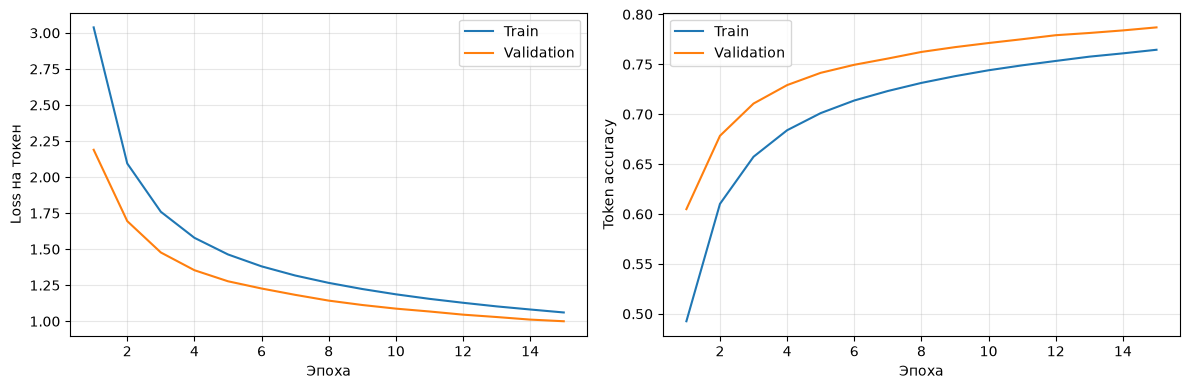

Обучение, минут: 29.95


In [7]:
history, training_seconds = fit(model, 'teacher_forcing', EPOCHS, LEARNING_RATE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, label in zip(axes, ['loss', 'accuracy'], ['Loss на токен', 'Token accuracy']):
    ax.plot(history.epoch, history[f'train_{metric}'], label='Train')
    ax.plot(history.epoch, history[f'val_{metric}'], label='Validation')
    ax.set(xlabel='Эпоха', ylabel=label)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
model = load_model('teacher_forcing')
print('Обучение, минут:', round(training_seconds / 60, 2))

# Testing

Make a function for text translation. Translate some text and evaluate model performance.

In [ ]:
@torch.no_grad()
def generate(model, source, max_len=MAX_TARGET_LEN - 1):
    model.eval()
    _, cache = model.hidden_states(source)
    token = torch.full((source.size(0),), BOS, dtype=torch.long, device=source.device)
    finished = torch.zeros(source.size(0), dtype=torch.bool, device=source.device)
    generated = []
    for step in range(max_len):
        logits, cache = model.step(token, cache)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(dim=-1)
        token = torch.where(finished, EOS, token)
        generated.append(token)
        finished = finished | token.eq(EOS)
        if finished.all():
            break
    return torch.stack(generated, dim=1)


def translate(text, tokenizer, model, max_len=MAX_TARGET_LEN - 1):
    ids = tokenizer.encode(text).ids
    if len(ids) > MAX_SOURCE_LEN:
        ids = ids[:MAX_SOURCE_LEN - 1] + [EOS]
        print('Вход обрезан до', MAX_SOURCE_LEN, 'токенов.')
    source = torch.tensor([ids], device=next(model.parameters()).device)
    max_len = min(max_len, model.max_length - len(ids))
    prediction = generate(model, source, max_len)[0].cpu().tolist()
    return tokenizer.decode(prediction).strip()

In [ ]:
evaluation = data['test'].to_pandas().groupby('key', sort=False).agg(
    ru=('ru', 'first'), references=('en', list), source_ids=('source_ids', 'first')
).reset_index(drop=True)
reference_streams = [
    [refs[i] if i < len(refs) else None for refs in evaluation.references]
    for i in range(evaluation.references.map(len).max())
]


def evaluate(model, name, output_dir=None):
    output_dir = ARTIFACTS if output_dir is None else Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    test_loss, test_accuracy = run_epoch(model, test_loader)
    hypotheses = []
    for start in tqdm(range(0, len(evaluation), BATCH_SIZE), desc=name):
        batch = evaluation.iloc[start:start + BATCH_SIZE]
        source = pad_sequence([torch.tensor(ids) for ids in batch.source_ids],
                              batch_first=True, padding_value=PAD).to(device)
        generated = generate(model, source).cpu().tolist()
        hypotheses.extend(tokenizer.decode(ids).strip() for ids in generated)
    bleu = BLEU(tokenize='13a')
    chrf = CHRF()
    metrics = {'Модель': name, 'BLEU': bleu.corpus_score(hypotheses, reference_streams).score,
               'chrF': chrf.corpus_score(hypotheses, reference_streams).score,
               'Exact match, %': 100 * np.mean([text in refs for text, refs in zip(hypotheses, evaluation.references)]),
               'Test loss (teacher forcing)': test_loss,
               'Token accuracy (teacher forcing), %': 100 * test_accuracy}
    translations = evaluation[['ru', 'references']].copy()
    translations['prediction'] = hypotheses
    translations.to_csv(output_dir / f'{name}_translations.csv', index=False)
    signatures = {'BLEU': str(bleu.get_signature()), 'chrF': str(chrf.get_signature())}
    (output_dir / f'{name}_metric_settings.json').write_text(json.dumps(signatures, indent=2))
    return metrics, hypotheses


baseline_metrics, baseline_predictions = evaluate(model, 'teacher_forcing')
display(pd.DataFrame([baseline_metrics]).set_index('Модель').round(3))
example_indices = np.random.default_rng(SEED).choice(len(evaluation), min(8, len(evaluation)), replace=False)
examples = evaluation.iloc[example_indices][['ru', 'references']].copy()
examples['teacher_forcing'] = [baseline_predictions[i] for i in example_indices]
with pd.option_context('display.max_colwidth', None):
    display(examples.reset_index(drop=True))
for text in ['Привет! Как дела?', 'Сегодня хорошая погода.', 'Я изучаю английский язык.']:
    print(text, ':', translate(text, tokenizer, model))

In [ ]:
repeat_text = 'Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.'
repeat_index = evaluation.index[evaluation.ru.eq(repeat_text)][0]
repeat_example = pd.DataFrame({
    'Текст': [repeat_text, ' / '.join(evaluation.loc[repeat_index, 'references']),
              baseline_predictions[repeat_index]],
}, index=['Исходный текст', 'Эталон', 'До дообучения'])
with pd.option_context('display.max_colwidth', None):
    display(repeat_example)

,Текст
Исходный текст,Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.
Эталон,A small forest fire can easily spread and quickly become a great conflagration.
До дообучения,A small fire can be able to be able to be able to be a huge fire and become a huge fire.


# Bonus

Train the model using its own predictions as inputs. The probability to use the predicted tokens instead of the ones from the dataset should increase as the training progresses. Train for one or two epochs. Evaluate the model, does the model perform better?

In [ ]:
BONUS_EPOCHS = 2
MAX_PREDICTION_PROBABILITY = 0.5
bonus_model = load_model('teacher_forcing')
bonus_history, bonus_seconds = fit(
    bonus_model, 'scheduled_sampling', BONUS_EPOCHS, learning_rate=1e-4,
    max_prediction_probability=MAX_PREDICTION_PROBABILITY,
)
display(bonus_history.round(4))
bonus_model = load_model('scheduled_sampling')
bonus_metrics, bonus_predictions = evaluate(bonus_model, 'scheduled_sampling')
results = pd.DataFrame([baseline_metrics, bonus_metrics]).set_index('Модель')
results['Обучение этапа, мин'] = [training_seconds / 60, bonus_seconds / 60]
results.to_csv(ARTIFACTS / 'comparison.csv')
display(results.round(3))
print('Изменение BLEU:', round(bonus_metrics['BLEU'] - baseline_metrics['BLEU'], 3))
print('Изменение chrF:', round(bonus_metrics['chrF'] - baseline_metrics['chrF'], 3))
examples['scheduled_sampling'] = [bonus_predictions[i] for i in example_indices]
with pd.option_context('display.max_colwidth', None):
    display(examples.reset_index(drop=True))

In [ ]:
repeat_example.loc['После дообучения', 'Текст'] = bonus_predictions[repeat_index]
with pd.option_context('display.max_colwidth', None):
    display(repeat_example)

In [ ]:
@torch.no_grad()
def mix_predictions_parallel(model, source, decoder_input, probability):
    was_training = model.training
    model.eval()
    logits = model(source, decoder_input)
    logits[:, :, [PAD, BOS]] = float('-inf')
    predicted = logits[:, :-1].argmax(dim=-1)
    use_prediction = torch.rand(predicted.shape, device=source.device) < probability
    use_prediction = use_prediction & decoder_input[:, 1:].ne(PAD)
    mixed = decoder_input.clone()
    mixed[:, 1:] = torch.where(use_prediction, predicted, decoder_input[:, 1:])
    model.train(was_training)
    return mixed

In [ ]:
PARALLEL_ARTIFACTS = Path('decoder_5_parallel_artifacts')
parallel_model = load_model('teacher_forcing')
parallel_history, parallel_seconds = fit(
    parallel_model, 'parallel_sampling', epochs=2, learning_rate=1e-4,
    max_prediction_probability=0.5,
    prediction_mixer=mix_predictions_parallel, output_dir=PARALLEL_ARTIFACTS,
)
tokenizer.save(str(PARALLEL_ARTIFACTS / 'tokenizer.json'))
display(parallel_history.round(4))
parallel_model = load_model('parallel_sampling', directory=PARALLEL_ARTIFACTS)
parallel_metrics, parallel_predictions = evaluate(
    parallel_model, 'parallel_sampling', output_dir=PARALLEL_ARTIFACTS,
)
comparison = pd.read_csv(ARTIFACTS / 'comparison.csv', index_col='Модель')
parallel_row = pd.DataFrame([parallel_metrics]).set_index('Модель')
parallel_row['Обучение этапа, мин'] = parallel_seconds / 60
comparison = pd.concat([comparison, parallel_row])
comparison.to_csv(PARALLEL_ARTIFACTS / 'comparison.csv')
display(comparison.round(3))
print('Ускорение дообучения:', round(comparison.loc['scheduled_sampling', 'Обучение этапа, мин']
                                     / (parallel_seconds / 60), 2))

comparison_examples = evaluation.iloc[example_indices][['ru', 'references']].copy()
for name in ['teacher_forcing', 'scheduled_sampling']:
    saved = pd.read_csv(ARTIFACTS / f'{name}_translations.csv', keep_default_na=False)
    comparison_examples[name] = comparison_examples.ru.map(saved.set_index('ru').prediction)
comparison_examples['parallel_sampling'] = [parallel_predictions[i] for i in example_indices]
with pd.option_context('display.max_colwidth', None):
    display(comparison_examples.reset_index(drop=True))

repeat_text = 'Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.'
repeat_index = evaluation.index[evaluation.ru.eq(repeat_text)][0]
repeat_example = pd.DataFrame({'Текст': [repeat_text, ' / '.join(evaluation.loc[repeat_index, 'references'])]},
                              index=['Исходный текст', 'Эталон'])
for name in ['teacher_forcing', 'scheduled_sampling']:
    saved = pd.read_csv(ARTIFACTS / f'{name}_translations.csv', keep_default_na=False)
    repeat_example.loc[name, 'Текст'] = saved.loc[saved.ru.eq(repeat_text), 'prediction'].iloc[0]
repeat_example.loc['parallel_sampling', 'Текст'] = parallel_predictions[repeat_index]
with pd.option_context('display.max_colwidth', None):
    display(repeat_example)

parallel_sampling, эпоха 1: train loss=1.1271, val loss=0.9718


parallel_sampling, эпоха 2: train loss=1.3074, val loss=0.9972


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,prediction_probability_end,lr
0,1,1.1271,0.9718,0.7631,0.7913,0.25,0.0001
1,2,1.3074,0.9972,0.7415,0.7879,0.50,0.0001


,BLEU,chrF,"Exact match, %",Test loss (teacher forcing),"Token accuracy (teacher forcing), %","Обучение этапа, мин"
Модель,,,,,,
teacher_forcing,32.458,49.854,15.308,1.739,65.879,29.955
scheduled_sampling,33.218,50.428,14.935,1.697,66.444,22.780
parallel_sampling,33.412,50.534,15.619,1.698,66.403,4.836


Ускорение дообучения: 4.71


,ru,references,teacher_forcing,scheduled_sampling,parallel_sampling
0,"Это было что-то, что я должен был запрограммировать.",[It would be something I'd have to program.],It was something I had to stop program.,It was something I had to avoid the program.,It was something I should've caused the program.
1,Ты где?,[Where are you?],Where are you?,Where are you?,Where are you?
2,Вот ваша сдача.,[Here is your change.],Here's your change.,Here's your change.,Here's your change.
3,"Вы что, собираетесь там весь день стоять?",[Are you just going to stand there all day?],Are you going to be there all day?,Are you going to be there all day?,Are you going to be there all day?
4,"Я женат, и у меня двое детей.",[I am married and have two children.],I'm married and two children have.,I'm married and two children have two children.,I'm married and two children have two children.
5,Почему люди идут в кино?,[Why do people go to the movies?],Why are people going to the movies?,Why are people going to the movies?,Why do people go to the movies?
6,Давайте рассмотрим наихудший вариант.,[Let's consider the worst that could happen.],Let's look at the original option.,Let's look at the court option.,Let's look at the court option.
7,"Мир — это книга. И те, кто не путешествуют, читают только одну страницу.","[The world is a book, and those who do not travel read only a page.]","The world is the book. It's not the book, reading only one of the page.","The world is a book. It's not the book, reading only one maps.","The world is the book. It's not the book, reading only one."


,Текст
Исходный текст,Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.
Эталон,A small forest fire can easily spread and quickly become a great conflagration.
teacher_forcing,A small fire can be able to be able to be able to be a huge fire and become a huge fire.
scheduled_sampling,The little fire is easy to be able to be able to be a huge fire and quickly fire.
parallel_sampling,The little fire is easy to be able to be able to be a huge fire and become a huge fire.


In [ ]:
PATIENCE = 3
PARALLEL_15_ARTIFACTS = Path('decoder_6_parallel_artifacts')
parallel_model = load_model('teacher_forcing')
parallel_history, parallel_seconds = fit(
    parallel_model, 'parallel_sampling_15', epochs=15, learning_rate=1e-4,
    max_prediction_probability=0.5,
    prediction_mixer=mix_predictions_parallel, output_dir=PARALLEL_15_ARTIFACTS,
)
tokenizer.save(str(PARALLEL_15_ARTIFACTS / 'tokenizer.json'))
display(parallel_history.round(4))
parallel_model = load_model('parallel_sampling_15', directory=PARALLEL_15_ARTIFACTS)
parallel_metrics, parallel_predictions = evaluate(
    parallel_model, 'parallel_sampling_15', output_dir=PARALLEL_15_ARTIFACTS,
)
comparison = pd.read_csv(Path('decoder_5_parallel_artifacts') / 'comparison.csv', index_col='Модель')
parallel_row = pd.DataFrame([parallel_metrics]).set_index('Модель')
parallel_row['Обучение этапа, мин'] = parallel_seconds / 60
comparison = pd.concat([comparison, parallel_row])
comparison.to_csv(PARALLEL_15_ARTIFACTS / 'comparison.csv')
display(comparison.round(3))


comparison_examples = evaluation.iloc[example_indices][['ru', 'references']].copy()
for name in ['teacher_forcing', 'scheduled_sampling']:
    saved = pd.read_csv(ARTIFACTS / f'{name}_translations.csv', keep_default_na=False)
    comparison_examples[name] = comparison_examples.ru.map(saved.set_index('ru').prediction)
comparison_examples['parallel_sampling_15'] = [parallel_predictions[i] for i in example_indices]
with pd.option_context('display.max_colwidth', None):
    display(comparison_examples.reset_index(drop=True))

repeat_text = 'Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.'
repeat_index = evaluation.index[evaluation.ru.eq(repeat_text)][0]
repeat_example = pd.DataFrame({'Текст': [repeat_text, ' / '.join(evaluation.loc[repeat_index, 'references'])]},
                              index=['Исходный текст', 'Эталон'])
for name in ['teacher_forcing', 'scheduled_sampling']:
    saved = pd.read_csv(ARTIFACTS / f'{name}_translations.csv', keep_default_na=False)
    repeat_example.loc[name, 'Текст'] = saved.loc[saved.ru.eq(repeat_text), 'prediction'].iloc[0]
repeat_example.loc['parallel_sampling_15', 'Текст'] = parallel_predictions[repeat_index]
with pd.option_context('display.max_colwidth', None):
    display(repeat_example)

parallel_sampling_15, эпоха 1: train loss=1.0215, val loss=0.9627


parallel_sampling_15, эпоха 2: train loss=1.0392, val loss=0.9570


parallel_sampling_15, эпоха 3: train loss=1.0623, val loss=0.9529


parallel_sampling_15, эпоха 4: train loss=1.0848, val loss=0.9503


parallel_sampling_15, эпоха 5: train loss=1.1057, val loss=0.9470


...

parallel_sampling_15, эпоха 12: train loss=1.2173, val loss=0.9460


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,prediction_probability_end,lr
0,1,1.0215,0.9627,0.7734,0.7934,0.0333,0.0001
1,2,1.0392,0.9570,0.7731,0.7946,0.0667,0.0001
2,3,1.0623,0.9529,0.7713,0.7950,0.1000,0.0001
3,4,1.0848,0.9503,0.7691,0.7955,0.1333,0.0001
4,5,1.1057,0.9470,0.7670,0.7958,0.1667,0.0001
5,6,1.1253,0.9477,0.7650,0.7961,0.2000,0.0001
6,7,1.1449,0.9479,0.7624,0.7961,0.2333,0.0001
7,8,1.1505,0.9432,0.7623,0.7972,0.2667,0.0000
8,9,1.1685,0.9428,0.7601,0.7969,0.3000,0.0000
9,10,1.1872,0.9445,0.7575,0.7970,0.3333,0.0000


,BLEU,chrF,"Exact match, %",Test loss (teacher forcing),"Token accuracy (teacher forcing), %","Обучение этапа, мин"
Модель,,,,,,
teacher_forcing,32.458,49.854,15.308,1.739,65.879,29.955
scheduled_sampling,33.218,50.428,14.935,1.697,66.444,22.780
parallel_sampling,33.412,50.534,15.619,1.698,66.403,4.836
parallel_sampling_15,34.289,51.619,16.055,1.659,67.262,29.000


,ru,references,teacher_forcing,scheduled_sampling,parallel_sampling_15
0,"Это было что-то, что я должен был запрограммировать.",[It would be something I'd have to program.],It was something I had to stop program.,It was something I had to avoid the program.,It was something I had to avoid the program.
1,Ты где?,[Where are you?],Where are you?,Where are you?,Where are you?
2,Вот ваша сдача.,[Here is your change.],Here's your change.,Here's your change.,Here's your change.
3,"Вы что, собираетесь там весь день стоять?",[Are you just going to stand there all day?],Are you going to be there all day?,Are you going to be there all day?,Are you going to be there all day?
4,"Я женат, и у меня двое детей.",[I am married and have two children.],I'm married and two children have.,I'm married and two children have two children.,I'm married and two children.
5,Почему люди идут в кино?,[Why do people go to the movies?],Why are people going to the movies?,Why are people going to the movies?,Why do people go to the movies?
6,Давайте рассмотрим наихудший вариант.,[Let's consider the worst that could happen.],Let's look at the original option.,Let's look at the court option.,Let's look at the most difficult option.
7,"Мир — это книга. И те, кто не путешествуют, читают только одну страницу.","[The world is a book, and those who do not travel read only a page.]","The world is the book. It's not the book, reading only one of the page.","The world is a book. It's not the book, reading only one maps.",The world is a book. It's not the book. It's only one maps.


,Текст
Исходный текст,Маленький огонь в лесу может легко распространиться и быстро стать огромным пожаром.
Эталон,A small forest fire can easily spread and quickly become a great conflagration.
teacher_forcing,A small fire can be able to be able to be able to be a huge fire and become a huge fire.
scheduled_sampling,The little fire is easy to be able to be able to be a huge fire and quickly fire.
parallel_sampling_15,The small fire can be spread down and light fire quickly as to become a huge fire.
